# Praktikum 2 - FAISS Flat dan IVF+PQ

**Nama:** Agus

**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js06-ann-approximate-nearest-neighbors/praktikum-2)

## Langkah 0 - Persiapan Lingkungan

In [1]:
import sys
import numpy as np
np.random.seed(42)
print("Kernel:", sys.executable)

import faiss
faiss.omp_set_num_threads(4)


Kernel: /Volumes/External/miniconda3/envs/ml-praktikum/bin/python


## Langkah 1 - Import Library

In [2]:
import numpy as np
import faiss
import matplotlib.pyplot as plt
import time


## Langkah 2 - Buat dataset 2D sederhana

In [3]:
# 1. Buat dataset 2D sederhana
np.random.seed(42)
X = np.random.rand(1000, 2).astype('float32')  # 1000 titik 2D
query = np.array([[0.5, 0.5]], dtype='float32')  # query di tengah


## Langkah 3 - Exact NN dengan IndexFlatL2 (brute force tapi cepat)

In [4]:
# 2. Exact NN dengan IndexFlatL2 (brute force tapi cepat)
index_flat = faiss.IndexFlatL2(2)   # L2 = Euclidean distance
index_flat.add(X)

start = time.time()
D_flat, I_flat = index_flat.search(query, 3)  # cari 3 tetangga terdekat
end = time.time()
time_flat = end - start


## Langkah 4 - IVF + PQ (Approximate)

In [5]:
# 3. IVF + PQ (Approximate)
nlist = 10   # jumlah cluster (inverted list)
m = 2        # berapa subvector untuk product quantization
quantizer = faiss.IndexFlatL2(2)   # dipakai IVF untuk cluster awal
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)  # 8 bit per subvector

index_ivfpq.train(X)  # training centroid
index_ivfpq.add(X)

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.time()
time_ivfpq = end - start


WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points


## Langkah 5 - Print hasil

In [6]:
# 4. Print hasil
print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print("Waktu Exact:", time_flat)
print("Waktu IVF+PQ:", time_ivfpq)


Exact NN (Flat) indices: [[137 170 750]] distances: [[0.00013095 0.00077404 0.00079751]]
IVF+PQ indices: [[137 170 750]] distances: [[0.00012945 0.00079226 0.00080067]]
Waktu Exact: 0.011131048202514648
Waktu IVF+PQ: 0.012190103530883789


## Langkah 6 - Visualisasi

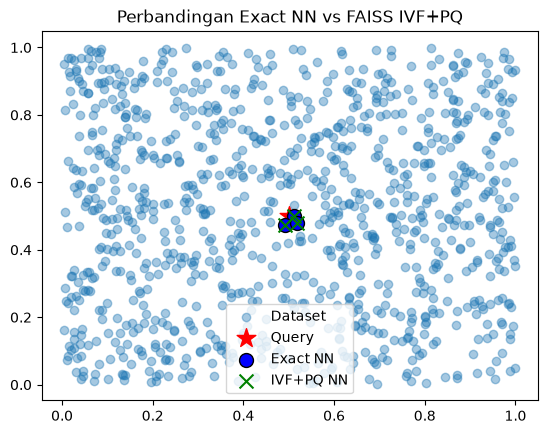

In [7]:
# 5. Visualisasi
plt.scatter(X[:,0], X[:,1], alpha=0.4, label="Dataset")
plt.scatter(query[:,0], query[:,1], c='red', marker='*', s=200, label="Query")

# Tetangga dari Flat
plt.scatter(X[I_flat[0],0], X[I_flat[0],1], c='blue', s=100, edgecolor='k', label="Exact NN")

# Tetangga dari IVF+PQ
plt.scatter(X[I_ivfpq[0],0], X[I_ivfpq[0],1], c='green', marker='x', s=100, label="IVF+PQ NN")

plt.legend()
plt.title("Perbandingan Exact NN vs FAISS IVF+PQ")
plt.show()


## Percobaan Tambahan - Variasi Metrik, Ukuran, dan Dimensi

Bandingkan 1.000 dan 1.000.000 baris, 2D dan 5D, serta Euclidean dan Cosine. Setiap pasangan memakai dataset/query dan k yang sama. Exact menggunakan FAISS Flat sebagai referensi. Cosine menggunakan normalisasi L2 pada FAISS. Satu query memberi pengukuran ilustratif, bukan benchmark latency yang stabil.

FAISS dan HNSW l2 mengembalikan **jarak Euclidean kuadrat**; scikit-learn NearestNeighbors mengembalikan jarak Euclidean. Urutan tetangga tetap dapat dibandingkan, tetapi nilai jaraknya harus disetarakan lebih dahulu.

In [8]:
import gc
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from annoy import AnnoyIndex
import faiss
import hnswlib


In [9]:
def recall_at_k(indices, truth, k):
    return sum(len(set(a[:k]) & set(b[:k])) for a, b in zip(indices, truth)) / (len(truth) * k)

def prepare_metric(X, query, metric):
    X = np.ascontiguousarray(X, dtype=np.float32)
    query = np.ascontiguousarray(query, dtype=np.float32)
    if metric == 'cosine':
        X = X.copy()
        query = query.copy()
        faiss.normalize_L2(X)
        faiss.normalize_L2(query)
    return X, query

def experiment_ann(n, dim, metric, algorithm, trees=8):
    rng = np.random.RandomState(42)
    X = rng.random_sample((n, dim)).astype(np.float32)
    query = rng.random_sample((1, dim)).astype(np.float32)
    X, query = prepare_metric(X, query, metric)
    k = 5
    start = time.perf_counter()
    exact = faiss.IndexFlatL2(dim) if metric == 'euclidean' else faiss.IndexFlatIP(dim)
    exact.add(X)
    exact_build = time.perf_counter() - start
    start = time.perf_counter()
    exact_D, truth = exact.search(query, k)
    exact_time = time.perf_counter() - start
    start = time.perf_counter()
    if algorithm == 'Annoy':
        index = AnnoyIndex(dim, 'euclidean' if metric == 'euclidean' else 'angular')
        index.set_seed(42)
        for i, vec in enumerate(X):
            index.add_item(i, vec)
        index.build(trees)
        build = time.perf_counter() - start
        start = time.perf_counter()
        ids, values = index.get_nns_by_vector(query[0], k, include_distances=True)
        pred = np.array([ids])
    elif algorithm == 'FAISS IVF+PQ':
        native = faiss.METRIC_L2 if metric == 'euclidean' else faiss.METRIC_INNER_PRODUCT
        quantizer = faiss.IndexFlatL2(dim) if metric == 'euclidean' else faiss.IndexFlatIP(dim)
        # m harus membagi dim: m=2 untuk 2D, m=5 untuk 5D.
        index = faiss.IndexIVFPQ(quantizer, dim, 10, dim, 8, native)
        index.train(X)
        index.add(X)
        build = time.perf_counter() - start
        start = time.perf_counter()
        values, pred = index.search(query, k)
    else:
        index = hnswlib.Index(space='l2' if metric == 'euclidean' else 'cosine', dim=dim)
        index.init_index(max_elements=n, ef_construction=100, M=16, random_seed=42)
        index.add_items(X)
        index.set_ef(50)
        build = time.perf_counter() - start
        start = time.perf_counter()
        pred, values = index.knn_query(query, k=k)
    query_time = time.perf_counter() - start
    result = {'Model': algorithm, 'Metrik': metric, 'Dimensi': dim, 'Jumlah data': n,
        'Tree': trees if algorithm == 'Annoy' else np.nan,
        'Index Exact': truth[0].tolist(), 'Index ANN': pred[0].tolist(),
        'Recall@5': recall_at_k(pred, truth, k),
        'Build Exact (s)': exact_build, 'Build ANN (s)': build,
        'Query Exact (ms)': exact_time * 1000, 'Query ANN (ms)': query_time * 1000}
    del exact, index, X
    gc.collect()
    return result


In [10]:
experiment_rows = []
for n in [1000, 1_000_000]:
    for dim in [2, 5]:
        for metric in ['euclidean', 'cosine']:
            print(f'Eksperimen: n={n}, dim={dim}, metric={metric}')
            experiment_rows.append(experiment_ann(n, dim, metric, 'FAISS IVF+PQ'))
display(pd.DataFrame(experiment_rows).round(6))


Eksperimen: n=1000, dim=2, metric=euclidean
Eksperimen: n=1000, dim=2, metric=cosine


Eksperimen: n=1000, dim=5, metric=euclidean
Eksperimen: n=1000, dim=5, metric=cosine
Eksperimen: n=1000000, dim=2, metric=euclidean


WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please provide at least 9984 training points
WARNING clustering 1000 points to 256 centroids: please prov

Eksperimen: n=1000000, dim=2, metric=cosine


Eksperimen: n=1000000, dim=5, metric=euclidean


Eksperimen: n=1000000, dim=5, metric=cosine


,Model,Metrik,Dimensi,Jumlah data,Tree,Index Exact,Index ANN,Recall@5,Build Exact (s),Build ANN (s),Query Exact (ms),Query ANN (ms)
0,FAISS IVF+PQ,euclidean,2,1000,NaN,"[112, 535, 777, 246, 763]","[112, 777, 548, 547, 427]",0.4,0.000022,0.006320,0.047667,0.011333
1,FAISS IVF+PQ,cosine,2,1000,NaN,"[738, 183, 561, 91, 244]","[91, 26, 965, 513, 893]",0.2,0.000012,0.002793,0.023459,0.025833
2,FAISS IVF+PQ,euclidean,5,1000,NaN,"[988, 780, 27, 943, 93]","[988, 780, 27, 943, 93]",1.0,0.000016,0.007133,0.013042,0.017250
3,FAISS IVF+PQ,cosine,5,1000,NaN,"[988, 943, 780, 332, 27]","[988, 943, 780, 332, 27]",1.0,0.000013,0.006682,0.010583,0.016250
4,FAISS IVF+PQ,euclidean,2,1000000,NaN,"[132774, 119034, 511191, 482199, 913140]","[132774, 410129, 511191, 913140, 119034]",0.8,0.000695,0.440266,2.240750,0.242417
5,FAISS IVF+PQ,cosine,2,1000000,NaN,"[737055, 47587, 43272, 18017, 8795]","[88068, 72833, 37751, 34876, 30476]",0.0,0.000551,0.439878,0.187958,0.172750
6,FAISS IVF+PQ,euclidean,5,1000000,NaN,"[901095, 495168, 561017, 163986, 185734]","[901095, 561017, 495168, 163986, 185734]",1.0,0.001827,1.052415,2.264667,0.210792
7,FAISS IVF+PQ,cosine,5,1000000,NaN,"[653774, 135588, 561017, 901095, 211473]","[314338, 163986, 817864, 457619, 645966]",0.0,0.001184,1.124617,1.957667,0.201708


## Analisis

Recall@5 menunjukkan bagian tetangga exact yang ditemukan. Dimensi dan metrik mengubah urutan kedekatan. Waktu build dipisahkan dari waktu query. Hasil satu query perlu dibaca bersama recall, bukan waktu saja. Untuk IVF+PQ, jumlah subvector m harus membagi dimensi: digunakan m=2 pada 2D dan m=5 pada 5D. Training dengan 1.000 baris dapat memberi peringatan jumlah contoh yang kecil; kode dasar modul tetap dipertahankan.

## Catatan training PQ

Peringatan FAISS pada percobaan 1.000 data menyatakan jumlah data latih lebih kecil dari rekomendasi untuk 256 centroid PQ. Eksperimen tetap berjalan, mengikuti konfigurasi contoh modul, tetapi kualitas kuantisasi pada ukuran kecil perlu dibaca bersama recall.